In [1]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

In [2]:
folder_path = '/Users/Katie/Documents/MagAO-X/Data/ADC/2025A/2025-04-15_043943_alfcen_closed_loop_iz/camsci1'
image_files = [os.path.join(folder_path, file) for file in os.listdir(folder_path) if file.startswith("camsci1_") and file.endswith('.fits')]
image_files = sorted(image_files, key=lambda x: int(x.split('_')[-1].split('.')[0]))
i_images = [read_fits(img_path) for img_path in image_files]

folder_path = '/Users/Katie/Documents/MagAO-X/Data/ADC/2025A/2025-04-15_043943_alfcen_closed_loop_iz/camsci2'
image_files = [os.path.join(folder_path, file) for file in os.listdir(folder_path) if file.startswith("camsci2_") and file.endswith('.fits')]
image_files = sorted(image_files, key=lambda x: int(x.split('_')[-1].split('.')[0]))
z_images = [read_fits(img_path) for img_path in image_files]

print(f"Loaded {len(i_images)} iband images.")
print(f"Loaded {len(z_images)} zband images.")

Loaded 8859 iband images.
Loaded 2368 zband images.


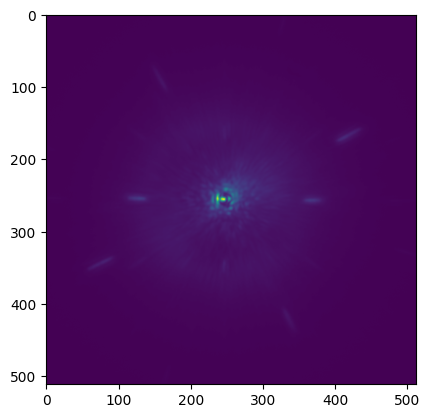

In [11]:
#stacking the iband images so we have almost the same of each
stacked = []

for i in range(0,len(i_images)-4,4):
    interval = [i,i+4]
    i_img = sum(i_images[interval[0]:interval[1]])/4
    stacked.append(i_img)

i_images = stacked
plt.imshow(i_images[0])

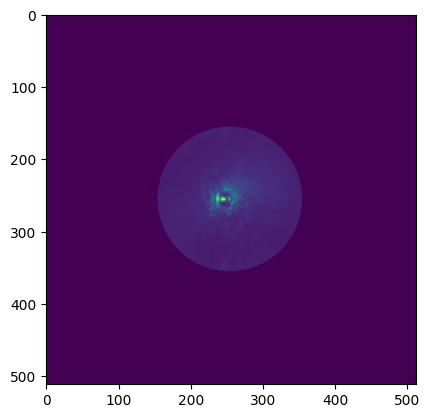

In [ ]:
#try on a single image before iterating through all of them
img = i_images[0]

Y, X = np.ogrid[0:512, 0:512]
M00 = np.sum(img)
M10 = np.sum(img * X)
M01 = np.sum(img * Y)
centroid = np.array([M10/M00,M01/M00])

x = centroid[0]
y = centroid[1]
r = 100

dist = np.sqrt((X - x)**2 + (Y - y)**2)
mask = dist <= r

masked = i_images[0] * mask
plt.imshow(masked)